In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/daniilnoobov/houston2013-split/Houston.mat
/kaggle/input/datasets/daniilnoobov/houston13-pca/HSI_PCA.npy
/kaggle/input/datasets/daniilnoobov/morphjepa-h13-wts/MorphJEPA_Houston13.pth


In [2]:
# --- Install Dependencies (Run once in Colab) ---
!pip install spectral

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.0/249.0 kB 5.8 MB/s eta 0:00:0000:01


In [3]:
# --- Standard Library & Utils ---
import os
import gc
import time
import random
import warnings
import numpy as np
import pandas as pd
from operator import truediv

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Scientific & HSI Processing ---
import scipy.io as sio
import spectral
from sklearn.decomposition import PCA, IncrementalPCA
from sklearn.metrics import (accuracy_score, classification_report,
                             cohen_kappa_score, confusion_matrix)
from sklearn.model_selection import train_test_split

# --- Morphology (Crucial for your MorphJEPA Data Loader) ---
from skimage import morphology
from skimage.morphology import square, disk

# --- PyTorch (Deep Learning Framework) ---
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, TensorDataset
from tqdm import tqdm

# --- Setup Device (Colab GPU check) ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Version: {torch.__version__}")
print(f"Device: {device}")

# Set seeds for reproducibility (Important for scientific papers)
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

PyTorch Version: 2.9.0+cu126
Device: cuda


In [4]:
## Global Parameters
#DLM = "PCA"
WS = 15
k = 15
mat_path = "/kaggle/input/datasets/daniilnoobov/houston2013-split/Houston.mat"
data = sio.loadmat(mat_path)
HSI = data['input']   # (145, 145, 200)
TR = data['TR']       # (145, 145)
TE = data['TE']       # (145, 145)
GT = TR + TE          # full label mask
Num_Classes = 15
target_names = ['Healthy grass', 'Stressed grass', 'Synthetic grass', 'Trees',
              'Soil', 'Water', 'Residential', 'Commercial', 'Road',
              'Highway', 'Railway', 'Parking Lot 1', 'Parking Lot 2',
              'Tennis Court', 'Running Track']

In [5]:
# --- 1. Refined ImageCubes (Only gets coordinates) ---
def get_valid_centers(HSI, GT, WS, remove_zero_labels=False):
    """
    Returns a list of valid (row, col) tuples for patch centers.
    Does NOT extract pixels, saving RAM.
    """
    H, W, _ = HSI.shape
    half = WS // 2
    centers = []

    # Define valid range to avoid boundary issues
    # We add extra margin if we need super-patches later
    margin = half + 5 # Safety margin for morphological padding

    r_min, r_max = margin, H - margin
    c_min, c_max = margin, W - margin

    for r in range(r_min, r_max):
        for c in range(c_min, c_max):
            label = GT[r, c]
            # For Pre-training: Keep everything (remove_zero_labels=False)
            # For Fine-tuning: Keep only labeled (remove_zero_labels=True)
            if remove_zero_labels and label == 0:
                continue
            centers.append((r, c))

    return centers

In [6]:
class FullSceneMorphDataset(Dataset):
    def __init__(self, hsi_image, centers, patch_size=15, morph_kernel_size=3):
        """
        Stores the FULL SCENE in memory (efficient) and slices on-the-fly.
        Pre-computes morphology on the full scene once.
        """
        print("⚡ Processing Full Scene Morphology (Seconds, not Hours)...")
        self.patch_size = patch_size
        self.pad = patch_size // 2
        
        # 1. Fix Deprecation: Use simple numpy array for square kernel
        # This replaces 'square(3)' which caused your warning
        selem = np.ones((morph_kernel_size, morph_kernel_size), dtype=bool)
        
        # 2. Pad the Full Scene (Mirror padding to handle edges)
        # We pad the big image once so we don't worry about borders later
        self.hsi_pad = np.pad(hsi_image, ((self.pad, self.pad), (self.pad, self.pad), (0, 0)), mode='symmetric')
        
        # 3. Compute Full Morphological Scenes
        # We create two new "Ghost" hyperspectral cubes: one fully Opened, one fully Closed
        self.hsi_open = np.zeros_like(self.hsi_pad)
        self.hsi_close = np.zeros_like(self.hsi_pad)
        
        # Loop over bands (Only 15 iterations!)
        for b in range(hsi_image.shape[-1]):
            # Morph the padded band
            band_img = self.hsi_pad[:, :, b]
            self.hsi_open[:, :, b] = morphology.opening(band_img, selem)
            self.hsi_close[:, :, b] = morphology.closing(band_img, selem)
            
        print("✅ Full Scene Processing Complete.")
        
        # Adjust centers to account for the padding we added to the scene
        # Original (r, c) -> New (r + pad, c + pad)
        self.centers = [(r + self.pad, c + self.pad) for r, c in centers]

    def __len__(self):
        return len(self.centers)

    def __getitem__(self, idx):
        r, c = self.centers[idx]
        
        # Calculate start/end for slicing
        start_r = r - self.pad
        end_r = start_r + self.patch_size
        start_c = c - self.pad
        end_c = start_c + self.patch_size
        
        # 4. Instant Slicing (No math, just memory access)
        # We slice from the pre-computed full scenes
        t_context = self.hsi_pad[start_r:end_r, start_c:end_c, :]
        t_open = self.hsi_open[start_r:end_r, start_c:end_c, :]
        t_close = self.hsi_close[start_r:end_r, start_c:end_c, :]
        
        # Convert to Tensor (C, H, W)
        # .copy() is needed because numpy slices can be non-contiguous
        x_context = torch.from_numpy(t_context.copy()).permute(2, 0, 1).float()
        x_open = torch.from_numpy(t_open.copy()).permute(2, 0, 1).float()
        x_close = torch.from_numpy(t_close.copy()).permute(2, 0, 1).float()
        
        return x_context, x_open, x_close

In [7]:
import numpy as np

HSI_PCA = np.load("/kaggle/input/datasets/daniilnoobov/houston13-pca/HSI_PCA.npy")

In [19]:
# 2. Normalize to [0, 1]
# Formula: (X - Min) / (Max - Min)
min_val = HSI.min()
max_val = HSI.max()

HSI_Norm = (HSI - min_val) / (max_val - min_val)

print(f"New Max: {HSI_Norm.max()}") # Should be 1.0
print(f"New Min: {HSI_Norm.min()}") # Should be 0.0

New Max: 1.0
New Min: 0.0


In [8]:
# --- 3. Usage Example ---
# Assuming 'HSI_PCA' is your (H, W, 15) numpy array from DLMethod
#HSI_PCA = DLMethod(DLM, HSI, NC=k)

# 2. Normalize to [0, 1]
# Formula: (X - Min) / (Max - Min)
min_val = HSI_PCA.min()
max_val = HSI_PCA.max()

HSI_PCA_Norm = (HSI_PCA - min_val) / (max_val - min_val)

print(f"New Max: {HSI_PCA_Norm.max()}") # Should be 1.0
print(f"New Min: {HSI_PCA_Norm.min()}") # Should be 0.0

# Step A: Get Centers (Pre-training = All pixels)
train_centers = get_valid_centers(HSI_PCA, GT, WS=15, remove_zero_labels=False)


# Step B: Create Dataset
#pretrain_dataset = MorphologicalProfileDataset(HSI_PCA, train_centers, patch_size=15)
pretrain_dataset = FullSceneMorphDataset(HSI_PCA_Norm, train_centers, patch_size=15)


# For Pre-training (Enable Augmentation)
# pretrain_dataset = MorphologicalProfileDataset(
#    HSI_PCA, train_centers, patch_size=15, augment=True)

# For Validation/Testing later (Disable Augmentation)
# val_dataset = MorphologicalProfileDataset(
#    HSI_PCA, val_centers, patch_size=15, augment=False)

# Step C: Create Loader
pretrain_loader = DataLoader(pretrain_dataset, batch_size=128, shuffle=True, num_workers=2)

# 3. Check speed
print("Testing load speed...")
import time
t0 = time.time()
batch = next(iter(pretrain_loader))
print(f"Loaded batch of shape {batch[0].shape} in {time.time()-t0:.4f} seconds!")

# Check one batch
batch = next(iter(pretrain_loader))

# Unpack the tuple (Order: Context, Open, Close)
context, target_open, target_close = batch 

print("Context Shape:", context.shape)       # Should be [128, 15, 15, 15]
print("Target Open Shape:", target_open.shape) # Should be [128, 15, 15, 15]
print("Target Close Shape:", target_close.shape) # Should be [128, 15, 15, 15]

New Max: 1.0
New Min: 0.0
⚡ Processing Full Scene Morphology (Seconds, not Hours)...
✅ Full Scene Processing Complete.
Testing load speed...
Loaded batch of shape torch.Size([128, 15, 15, 15]) in 0.2097 seconds!
Context Shape: torch.Size([128, 15, 15, 15])
Target Open Shape: torch.Size([128, 15, 15, 15])
Target Close Shape: torch.Size([128, 15, 15, 15])


Estimating morphological attenuation factor α...
(Using pretrain_dataset's pre-computed morphological scenes)

Classes found: [np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9), np.uint8(10), np.uint8(11), np.uint8(12), np.uint8(13), np.uint8(14), np.uint8(15)]
Pixels per class: [1059, 1054, 1064, 1072, 1056, 1036, 1053, 1053, 1041, 1056, 143, 285, 247, 473, 505]

EMPIRICAL ALPHA ESTIMATION (Assumption A1 Verification)

  Operator: Opening (White Top-Hat)
    Mean α̂         : 0.5549
    95th Percentile: 1.0856
    % pairs α̂ < 0.5: 51.3%
    % pairs α̂ < 1.0: 93.1%

  Operator: Closing (Black Top-Hat)
    Mean α̂         : 0.5557
    95th Percentile: 1.1075
    % pairs α̂ < 0.5: 51.2%
    % pairs α̂ < 1.0: 92.5%

  → α̂ ≪ 1 confirms Assumption A1 holds empirically.


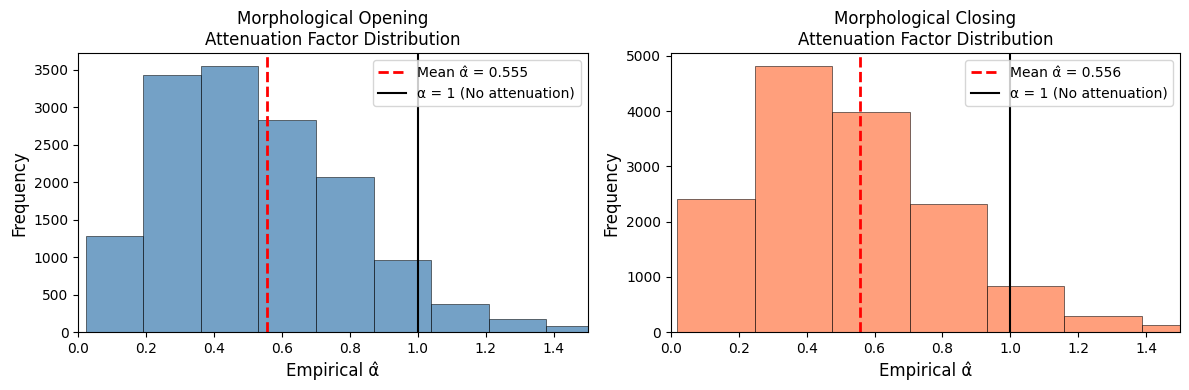

Figure saved: alpha_estimation_houston2013.pdf


In [9]:
# ============================================================
# ALPHA ESTIMATION: Empirical Verification of Assumption A1
# ============================================================
# Must run AFTER pretrain_dataset is created (hsi_open/hsi_close available)
# Must run AFTER HSI_PCA_Norm, GT, TR, TE are loaded

def estimate_morphological_attenuation(hsi_norm, hsi_open_pad, hsi_close_pad,
                                        gt, patch_size=15, 
                                        n_pairs_per_class=1000,
                                        seed=42):
    """
    Estimates empirical alpha (Lipschitz constant of residual mapping r_m).
    
    Uses same-class patch pairs from the TEST set (TE) since those are 
    the densely labeled pixels. Computes ratio:
        alpha_hat = ||r_m(n1) - r_m(n2)|| / ||x1 - x2||
    where r_m(n) = x - x^(m) is the top-hat / black-hat residual.
    
    Args:
        hsi_norm:      (H, W, B) normalized HSI scene
        hsi_open_pad:  padded opened scene from pretrain_dataset.hsi_open
        hsi_close_pad: padded closed scene from pretrain_dataset.hsi_close
        gt:            (H, W) full label map (TR + TE)
        patch_size:    must match your model (15)
        n_pairs_per_class: Monte Carlo pairs to sample per class
    """
    np.random.seed(seed)
    pad = patch_size // 2
    H, W, B = hsi_norm.shape
    
    # --- Step 1: Unpad the morphological scenes back to original size ---
    # pretrain_dataset pads by 'pad' on each side
    # So unpadded version is [pad:-pad, pad:-pad, :]
    hsi_open_unpad  = hsi_open_pad[pad:-pad,  pad:-pad,  :]
    hsi_close_unpad = hsi_close_pad[pad:-pad, pad:-pad, :]
    
    # --- Step 2: Compute residuals (top-hat transforms) ---
    # r_open(n)  = x - x^(o)  [White Top-Hat: removes bright structures]
    # r_close(n) = x - x^(c)  [Black Top-Hat: removes dark structures]
    residual_open  = hsi_norm - hsi_open_unpad   # (H, W, B)
    residual_close = hsi_norm - hsi_close_unpad  # (H, W, B)
    
    # --- Step 3: Get labeled pixel locations by class ---
    # Use TE pixels — these are the densely labeled evaluation pixels
    te_rows, te_cols = np.nonzero(TE)
    
    # Group by class
    class_pixels = {}
    for r, c in zip(te_rows, te_cols):
        label = gt[r, c]
        if label == 0:
            continue
        if label not in class_pixels:
            class_pixels[label] = []
        class_pixels[label].append((r, c))
    
    print(f"Classes found: {sorted(class_pixels.keys())}")
    print(f"Pixels per class: "
          f"{[len(v) for v in class_pixels.values()]}")
    
    # --- Step 4: Monte Carlo sampling of same-class pairs ---
    ratios_open  = []
    ratios_close = []
    
    for cls, pixels in class_pixels.items():
        pixels = np.array(pixels)  # (N, 2)
        n = len(pixels)
        
        if n < 2:
            continue
            
        # Sample random pairs within same class
        n_pairs = min(n_pairs_per_class, n * (n-1) // 2)
        
        for _ in range(n_pairs):
            # Pick two different pixels from same class
            idx1, idx2 = np.random.choice(n, 2, replace=False)
            r1, c1 = pixels[idx1]
            r2, c2 = pixels[idx2]
            
            # Flatten center pixel + small neighborhood for norm
            # Using center pixel only (single pixel comparison)
            x1 = hsi_norm[r1, c1, :]      # (B,)
            x2 = hsi_norm[r2, c2, :]      # (B,)
            
            res_o1 = residual_open[r1, c1, :]
            res_o2 = residual_open[r2, c2, :]
            
            res_c1 = residual_close[r1, c1, :]
            res_c2 = residual_close[r2, c2, :]
            
            # Compute norms
            orig_diff = np.linalg.norm(x1 - x2)
            
            if orig_diff < 1e-6:   # skip identical pixels
                continue
            
            res_o_diff = np.linalg.norm(res_o1 - res_o2)
            res_c_diff = np.linalg.norm(res_c1 - res_c2)
            
            ratios_open.append(res_o_diff  / orig_diff)
            ratios_close.append(res_c_diff / orig_diff)
    
    ratios_open  = np.array(ratios_open)
    ratios_close = np.array(ratios_close)
    
    return ratios_open, ratios_close


# --- Run Estimation ---
print("Estimating morphological attenuation factor α...")
print("(Using pretrain_dataset's pre-computed morphological scenes)\n")

ratios_open, ratios_close = estimate_morphological_attenuation(
    hsi_norm      = HSI_PCA_Norm,
    hsi_open_pad  = pretrain_dataset.hsi_open,   # already computed!
    hsi_close_pad = pretrain_dataset.hsi_close,  # already computed!
    gt            = GT,
    patch_size    = 15,
    n_pairs_per_class = 1000
)

# --- Report Results ---
print("\n" + "="*55)
print("EMPIRICAL ALPHA ESTIMATION (Assumption A1 Verification)")
print("="*55)

for name, ratios in [("Opening (White Top-Hat)", ratios_open),
                      ("Closing (Black Top-Hat)", ratios_close)]:
    mean_a  = ratios.mean()
    p95_a   = np.percentile(ratios, 95)
    pct_lt_half = (ratios < 0.5).mean() * 100
    pct_lt_one  = (ratios < 1.0).mean() * 100
    
    print(f"\n  Operator: {name}")
    print(f"    Mean α̂         : {mean_a:.4f}")
    print(f"    95th Percentile: {p95_a:.4f}")
    print(f"    % pairs α̂ < 0.5: {pct_lt_half:.1f}%")
    print(f"    % pairs α̂ < 1.0: {pct_lt_one:.1f}%")

print("\n  → α̂ ≪ 1 confirms Assumption A1 holds empirically.")
print("="*55)

# --- Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, ratios, name, color in zip(
    axes,
    [ratios_open, ratios_close],
    ["Opening", "Closing"],
    ["steelblue", "coral"]
):
    ax.hist(ratios, bins=50, color=color, alpha=0.75, 
            edgecolor='black', linewidth=0.5)
    ax.axvline(ratios.mean(), color='red', 
               linestyle='--', linewidth=2,
               label=f'Mean α̂ = {ratios.mean():.3f}')
    ax.axvline(1.0, color='black', 
               linestyle='-', linewidth=1.5,
               label='α = 1 (No attenuation)')
    ax.set_xlabel('Empirical α̂', fontsize=12)
    ax.set_ylabel('Frequency', fontsize=12)
    ax.set_title(f'Morphological {name}\nAttenuation Factor Distribution', 
                 fontsize=12)
    ax.legend(fontsize=10)
    ax.set_xlim(0, 1.5)

plt.tight_layout()
plt.savefig('alpha_estimation_houston2013.pdf', 
            bbox_inches='tight', dpi=150)
plt.show()
print("Figure saved: alpha_estimation_houston2013.pdf")

In [9]:
def estimate_alpha_patch_level(hsi_norm, hsi_open_pad, hsi_close_pad,
                                gt, patch_size=15,
                                n_pairs_per_class=500, seed=42):
    """
    Patch-level alpha estimation — correct level of analysis
    since encoder operates on 15x15 patches not single pixels.
    """
    np.random.seed(seed)
    pad = patch_size // 2
    
    # Unpad morphological scenes
    hsi_open_unpad  = hsi_open_pad[pad:-pad,  pad:-pad, :]
    hsi_close_unpad = hsi_close_pad[pad:-pad, pad:-pad, :]
    
    # Residuals
    residual_open  = hsi_norm - hsi_open_unpad
    residual_close = hsi_norm - hsi_close_unpad
    
    # Get valid patch centers from TE pixels
    # Must be far enough from border to extract full patch
    H, W, B = hsi_norm.shape
    te_rows, te_cols = np.nonzero(TE)
    
    # Filter to valid patch centers (away from borders)
    valid_mask = ((te_rows >= pad) & (te_rows < H - pad) &
                  (te_cols >= pad) & (te_cols < W - pad))
    te_rows = te_rows[valid_mask]
    te_cols = te_cols[valid_mask]
    
    # Group by class
    class_pixels = {}
    for r, c in zip(te_rows, te_cols):
        label = gt[r, c]
        if label == 0:
            continue
        if label not in class_pixels:
            class_pixels[label] = []
        class_pixels[label].append((r, c))
    
    ratios_open  = []
    ratios_close = []
    
    for cls, pixels in class_pixels.items():
        pixels = np.array(pixels)
        n = len(pixels)
        if n < 2:
            continue
        
        n_pairs = min(n_pairs_per_class, n * (n-1) // 2)
        
        for _ in range(n_pairs):
            idx1, idx2 = np.random.choice(n, 2, replace=False)
            r1, c1 = pixels[idx1]
            r2, c2 = pixels[idx2]
            
            # Extract full 15x15xB patches and flatten
            p1 = hsi_norm[r1-pad:r1+pad+1, 
                          c1-pad:c1+pad+1, :].flatten()
            p2 = hsi_norm[r2-pad:r2+pad+1, 
                          c2-pad:c2+pad+1, :].flatten()
            
            ro1 = residual_open[r1-pad:r1+pad+1,
                                c1-pad:c1+pad+1, :].flatten()
            ro2 = residual_open[r2-pad:r2+pad+1,
                                c2-pad:c2+pad+1, :].flatten()
            
            rc1 = residual_close[r1-pad:r1+pad+1,
                                 c1-pad:c1+pad+1, :].flatten()
            rc2 = residual_close[r2-pad:r2+pad+1,
                                 c2-pad:c2+pad+1, :].flatten()
            
            orig_diff = np.linalg.norm(p1 - p2)
            if orig_diff < 1e-6:
                continue
            
            ratios_open.append(np.linalg.norm(ro1 - ro2) / orig_diff)
            ratios_close.append(np.linalg.norm(rc1 - rc2) / orig_diff)
    
    return np.array(ratios_open), np.array(ratios_close)


# Run patch-level estimation
print("Running PATCH-LEVEL alpha estimation...")
ratios_open_patch, ratios_close_patch = estimate_alpha_patch_level(
    hsi_norm      = HSI_PCA_Norm,
    hsi_open_pad  = pretrain_dataset.hsi_open,
    hsi_close_pad = pretrain_dataset.hsi_close,
    gt            = GT,
    patch_size    = 15,
    n_pairs_per_class = 500
)

for name, ratios in [("Opening", ratios_open_patch),
                      ("Closing", ratios_close_patch)]:
    print(f"\n{name}:")
    print(f"  Mean α̂          : {ratios.mean():.4f}")
    print(f"  Median α̂        : {np.median(ratios):.4f}")
    print(f"  95th Percentile : {np.percentile(ratios, 95):.4f}")
    print(f"  % pairs α̂ < 0.5 : {(ratios < 0.5).mean()*100:.1f}%")
    print(f"  % pairs α̂ < 1.0 : {(ratios < 1.0).mean()*100:.1f}%")

Running PATCH-LEVEL alpha estimation...

Opening:
  Mean α̂          : 0.4633
  Median α̂        : 0.4546
  95th Percentile : 0.7679
  % pairs α̂ < 0.5 : 61.5%
  % pairs α̂ < 1.0 : 100.0%

Closing:
  Mean α̂          : 0.4483
  Median α̂        : 0.4496
  95th Percentile : 0.7106
  % pairs α̂ < 0.5 : 64.0%
  % pairs α̂ < 1.0 : 100.0%


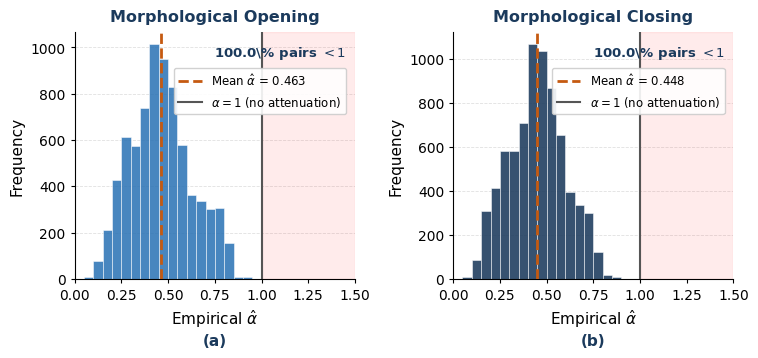

Saved: alpha_estimation_houston2013.pdf / .png


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import rcParams

# ── Style to match your existing figure ─────────────────────
rcParams['font.family']      = 'DejaVu Sans'
rcParams['font.size']        = 11
rcParams['axes.spines.top']  = False
rcParams['axes.spines.right']= False
rcParams['axes.spines.left'] = True
rcParams['axes.spines.bottom']= True

# Colours extracted from your figure
DARK_NAVY   = '#1B3A5C'   # darkest blue (selected cells)
MED_BLUE    = '#2E75B6'   # medium blue (histogram bars)
LIGHT_BLUE  = '#BDD7EE'   # lightest blue (non-selected)
ORANGE      = '#C55A11'   # orange accent (mean line)
GREY_LINE   = '#555555'   # alpha=1 boundary line

fig, axes = plt.subplots(
    1, 2,
    figsize=(8.5, 3.2),
    sharey=False,
    gridspec_kw={'wspace': 0.35}
)

data = [
    (ratios_open_patch,  'Morphological Opening', MED_BLUE),
    (ratios_close_patch, 'Morphological Closing', DARK_NAVY),
]

for ax, (ratios, title, bar_color) in zip(axes, data):

    # ── Histogram ───────────────────────────────────────────
    counts, edges, patches = ax.hist(
        ratios,
        bins=30,
        range=(0, 1.5),
        color=bar_color,
        alpha=0.88,
        edgecolor='white',
        linewidth=0.4,
        zorder=2
    )

    # ── Mean line (orange, matching your accent) ─────────────
    mean_val = ratios.mean()
    ax.axvline(
        mean_val,
        color=ORANGE,
        linestyle='--',
        linewidth=2.0,
        zorder=3,
        label=fr'Mean $\hat{{\alpha}}$ = {mean_val:.3f}'
    )

    # ── α = 1 boundary ───────────────────────────────────────
    ax.axvline(
        1.0,
        color=GREY_LINE,
        linestyle='-',
        linewidth=1.5,
        zorder=3,
        label=r'$\alpha = 1$ (no attenuation)'
    )

    # ── Shaded region right of α=1 (violation zone) ──────────
    ax.axvspan(
        1.0, 1.5,
        alpha=0.08,
        color='red',
        zorder=1
    )

    # ── Annotations ─────────────────────────────────────────
    pct_lt1 = (ratios < 1.0).mean() * 100
    ax.text(
        0.97, 0.95,
        fr'{pct_lt1:.1f}\% pairs $< 1$',
        transform=ax.transAxes,
        ha='right', va='top',
        fontsize=9.5,
        color=DARK_NAVY,
        fontweight='bold'
    )

    # ── Axis formatting ──────────────────────────────────────
    ax.set_title(title, fontsize=11.5, fontweight='bold',
                 color=DARK_NAVY, pad=8)
    ax.set_xlabel(r'Empirical $\hat{\alpha}$', fontsize=11)
    ax.set_ylabel('Frequency', fontsize=11)
    ax.set_xlim(0, 1.5)
    ax.tick_params(axis='both', labelsize=10)
    ax.yaxis.set_tick_params(length=3)
    ax.xaxis.set_tick_params(length=3)
    ax.grid(axis='y', color='#E0E0E0', linewidth=0.6,
            linestyle='--', zorder=0)
    ax.set_axisbelow(True)

    # ── Legend ───────────────────────────────────────────────
    ax.legend(
        fontsize=8.5,
        frameon=True,
        framealpha=0.9,
        edgecolor='#CCCCCC',
        loc='upper right',
        bbox_to_anchor=(0.99, 0.88)
    )

# ── Subfigure labels ─────────────────────────────────────────
for ax, label in zip(axes, ['(a)', '(b)']):
    ax.text(
        0.5, -0.22,
        label,
        transform=ax.transAxes,
        ha='center', va='top',
        fontsize=11, fontweight='bold',
        color=DARK_NAVY
    )

plt.savefig(
    'alpha_estimation_houston2013.pdf',
    bbox_inches='tight',
    dpi=300,
    facecolor='white'
)
plt.savefig(
    'alpha_estimation_houston2013.png',
    bbox_inches='tight',
    dpi=300,
    facecolor='white'
)
plt.show()
print("Saved: alpha_estimation_houston2013.pdf / .png")

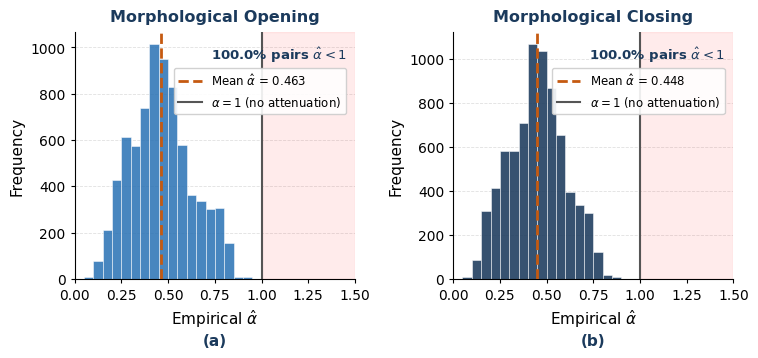

Saved: alpha_estimation_houston2013.pdf / .png


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

# ── Style to match your existing figure ─────────────────────
rcParams['font.family']       = 'DejaVu Sans'
rcParams['font.size']         = 11
rcParams['axes.spines.top']   = False
rcParams['axes.spines.right'] = False
rcParams['axes.spines.left']  = True
rcParams['axes.spines.bottom']= True

DARK_NAVY  = '#1B3A5C'
MED_BLUE   = '#2E75B6'
ORANGE     = '#C55A11'
GREY_LINE  = '#555555'

fig, axes = plt.subplots(
    1, 2,
    figsize=(8.5, 3.2),
    sharey=False,
    gridspec_kw={'wspace': 0.35}
)

data = [
    (ratios_open_patch,  'Morphological Opening', MED_BLUE),
    (ratios_close_patch, 'Morphological Closing', DARK_NAVY),
]

for ax, (ratios, title, bar_color) in zip(axes, data):

    # ── Histogram ───────────────────────────────────────────
    ax.hist(
        ratios,
        bins=30,
        range=(0, 1.5),
        color=bar_color,
        alpha=0.88,
        edgecolor='white',
        linewidth=0.4,
        zorder=2
    )

    # ── Mean line ────────────────────────────────────────────
    mean_val = ratios.mean()
    ax.axvline(
        mean_val,
        color=ORANGE,
        linestyle='--',
        linewidth=2.0,
        zorder=3,
        label=r'Mean $\hat{\alpha}$' + f' = {mean_val:.3f}'
    )

    # ── α = 1 boundary ───────────────────────────────────────
    ax.axvline(
        1.0,
        color=GREY_LINE,
        linestyle='-',
        linewidth=1.5,
        zorder=3,
        label=r'$\alpha = 1$ (no attenuation)'
    )

    # ── Shaded violation zone ────────────────────────────────
    ax.axvspan(
        1.0, 1.5,
        alpha=0.08,
        color='red',
        zorder=1
    )

    # ── Annotation ───────────────────────────────────────────
    pct_lt1 = (ratios < 1.0).mean() * 100
    ax.text(
        0.97, 0.95,
        r'$\mathbf{' + f'{pct_lt1:.1f}' + r'\%}$' 
        + r' pairs $\hat{\alpha} < 1$',
        transform=ax.transAxes,
        ha='right', va='top',
        fontsize=9.5,
        color=DARK_NAVY,
        fontweight='bold'
    )

    # ── Title ────────────────────────────────────────────────
    ax.set_title(
        title,
        fontsize=11.5,
        fontweight='bold',
        color=DARK_NAVY,
        pad=8
    )

    # ── Axis labels ──────────────────────────────────────────
    ax.set_xlabel(r'Empirical $\hat{\alpha}$', fontsize=11)
    ax.set_ylabel('Frequency', fontsize=11)
    ax.set_xlim(0, 1.5)
    ax.tick_params(axis='both', labelsize=10)
    ax.yaxis.set_tick_params(length=3)
    ax.xaxis.set_tick_params(length=3)
    ax.grid(
        axis='y',
        color='#E0E0E0',
        linewidth=0.6,
        linestyle='--',
        zorder=0
    )
    ax.set_axisbelow(True)

    # ── Legend ───────────────────────────────────────────────
    ax.legend(
        fontsize=8.5,
        frameon=True,
        framealpha=0.9,
        edgecolor='#CCCCCC',
        loc='upper right',
        bbox_to_anchor=(0.99, 0.88)
    )

# ── Subfigure labels ─────────────────────────────────────────
for ax, label in zip(axes, ['(a)', '(b)']):
    ax.text(
        0.5, -0.22,
        label,
        transform=ax.transAxes,
        ha='center', va='top',
        fontsize=11,
        fontweight='bold',
        color=DARK_NAVY
    )

plt.savefig(
    'alpha_estimation_houston2013.pdf',
    bbox_inches='tight',
    dpi=300,
    facecolor='white'
)
plt.savefig(
    'alpha_estimation_houston2013.png',
    bbox_inches='tight',
    dpi=300,
    facecolor='white'
)
plt.show()
print("Saved: alpha_estimation_houston2013.pdf / .png")

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# --- 1. The Spatial Branch (Query Generator) ---
# Captures local texture and broader geometric context
class SpatialBranch(nn.Module):
    def __init__(self, in_channels, out_dim):
        super().__init__()
        # Path A: Local Details (Standard 3x3)
        self.local_conv = nn.Conv2d(in_channels, out_dim // 2, kernel_size=3, padding=1)

        # Path B: Broader Context (Dilated 3x3)
        # Dilation=2 expands receptive field without losing resolution
        self.context_conv = nn.Conv2d(in_channels, out_dim // 2, kernel_size=3, padding=2, dilation=2)

        self.bn = nn.BatchNorm2d(out_dim)
        self.act = nn.GELU()

    def forward(self, x):
        # x: [Batch, C, H, W]
        feat_local = self.local_conv(x)
        feat_context = self.context_conv(x)

        # Concatenate features
        out = torch.cat([feat_local, feat_context], dim=1) # [B, out_dim, H, W]
        out = self.act(self.bn(out))
        return out

# --- 2. The Spectral Branch (Key/Value Generator) ---
# Captures material signatures (pixel-wise spectral logic)
class SpectralBranch(nn.Module):
    def __init__(self, in_channels, out_dim):
        super().__init__()
        # 1x1 Conv acts as a per-pixel MLP across spectral bands
        # It learns to mix bands to identify materials, ignoring spatial shape
        self.spectral_conv = nn.Conv2d(in_channels, out_dim, kernel_size=1)
        self.bn = nn.BatchNorm2d(out_dim)
        self.act = nn.GELU()

    def forward(self, x):
        return self.act(self.bn(self.spectral_conv(x)))

# --- 3. The Core Encoder: Hybrid Morph-ViT ---
class HybridMorphEncoder(nn.Module):
    def __init__(self, in_channels=15, embed_dim=128, patch_size=15):
        super().__init__()
        self.embed_dim = embed_dim

        # Feature Extractors
        self.spatial_branch = SpatialBranch(in_channels, embed_dim)
        self.spectral_branch = SpectralBranch(in_channels, embed_dim)

        # Fusion: Cross Attention
        # Spatial features (Query) ask Spectral features (Key/Value) for relevant info
        self.cross_attn = nn.MultiheadAttention(embed_dim, num_heads=4, batch_first=True)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

        # Feed Forward Network (Standard ViT block ending)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 2),
            nn.GELU(),
            nn.Linear(embed_dim * 2, embed_dim)
        )

        # Positional Encoding (Learnable)
        # 15x15 = 225 tokens
        self.pos_embed = nn.Parameter(torch.randn(1, patch_size*patch_size, embed_dim) * 0.02)

    def forward(self, x):
        # Input: [B, C, H, W]
        B, C, H, W = x.shape

        # 1. Extract Features
        q_map = self.spatial_branch(x)  # [B, D, H, W]
        kv_map = self.spectral_branch(x) # [B, D, H, W]

        # 2. Flatten for Attention [B, N, D]
        # N = H*W (Spatial Tokens)
        q = q_map.flatten(2).transpose(1, 2)   # [B, 225, 128]
        k = kv_map.flatten(2).transpose(1, 2)  # [B, 225, 128]
        v = k # Keys and Values are the same (Spectral features)

        # 3. Add Positional Embedding to Query (Spatial awareness)
        q = q + self.pos_embed

        # 4. Cross Attention Fusion
        # Query = Spatial Structure, Key/Value = Spectral Material
        attn_out, _ = self.cross_attn(query=q, key=k, value=v)

        # Residual + Norm
        x_fused = self.norm1(q + attn_out)

        # 5. Feed Forward
        x_fused = x_fused + self.ffn(self.norm2(x_fused))

        # 6. Global Average Pooling -> Final Representation Z
        # We average over all spatial tokens to get one vector per patch
        z = x_fused.mean(dim=1) # [B, 128]

        return z

# --- 4. The LeJEPA Projector ---
# Used during Pre-training to map Z to a high-dim Gaussian space
class LeJEPAHead(nn.Module):
    def __init__(self, input_dim=128, output_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, input_dim),
            nn.BatchNorm1d(input_dim),
            nn.GELU(),
            nn.Linear(input_dim, output_dim) # Project to higher dim for SIGReg
        )

    def forward(self, x):
        return self.net(x)

# --- 5. Linear Probe (For Evaluation) ---
# Simple classifier attached to the frozen encoder
class LinearProbe(nn.Module):
    def __init__(self, encoder, num_classes=15):
        super().__init__()
        self.encoder = encoder
        # Freeze the encoder!
        for param in self.encoder.parameters():
            param.requires_grad = False

        self.head = nn.Linear(encoder.embed_dim, num_classes)

    def forward(self, x):
        with torch.no_grad():
            features = self.encoder(x)
        return self.head(features)

# --- Sanity Check ---
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Random HSI Patch Batch [Batch, Bands, H, W]
    dummy_input = torch.randn(32, 15, 15, 15).to(device)

    # Initialize Model
    encoder = HybridMorphEncoder(in_channels=15, embed_dim=128).to(device)
    projector = LeJEPAHead(input_dim=128, output_dim=256).to(device)

    # Forward Pass
    z = encoder(dummy_input)
    z_proj = projector(z)

    print(f"Input Shape: {dummy_input.shape}")
    print(f"Encoder Output (Z) Shape: {z.shape}") # Should be [32, 128]
    print(f"Projector Output Shape: {z_proj.shape}") # Should be [32, 256]
    print("Model construction successful.")

Input Shape: torch.Size([32, 15, 15, 15])
Encoder Output (Z) Shape: torch.Size([32, 128])
Projector Output Shape: torch.Size([32, 256])
Model construction successful.


In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import time

# --- 1. The Stability Engine: SIGReg Loss (LeJEPA) ---
# Implements Sketched Epps-Pulley Test from Algorithm 1
class SIGRegLoss(nn.Module):
    def __init__(self, num_slices=1024, integration_points=17, integration_domain=5.0):
        super().__init__()
        self.num_slices = num_slices
        self.t_max = integration_domain
        self.num_points = integration_points

        # Pre-compute integration grid 't' (static)
        # Trapezoidal rule points between -5 and 5
        self.register_buffer('t_grid', torch.linspace(-self.t_max, self.t_max, self.num_points))

        # Theoretical CF of Standard Gaussian N(0,1): exp(-0.5 * t^2)
        # We also apply a Gaussian weighting window w(t) = exp(-0.5 * t^2) for the test stability
        # So the target to match is exp(-t^2) combined
        self.register_buffer('target_cf', torch.exp(-0.5 * self.t_grid**2))

    def forward(self, z):
        """
        z: [Batch, Dim] - The latent embeddings
        """
        B, D = z.shape
        device = z.device

        # 1. Generate Random Projections (The "Sketching")
        # Sample random directions on the hypersphere
        projections = torch.randn(D, self.num_slices, device=device) # [D, M]
        projections = F.normalize(projections, dim=0) # Normalize columns

        # 2. Project Embeddings onto Slices
        # x_proj: [Batch, M] -> Value of embedding along each random direction
        x_proj = z @ projections

        # 3. Compute Empirical Characteristic Function (ECF)
        # ECF(t) = (1/N) * sum(exp(i * t * x_proj))
        # We compute this for every 't' in our integration grid

        # Reshape for broadcasting: [Batch, M, 1] * [1, 1, T] -> [Batch, M, T]
        args = x_proj.unsqueeze(-1) * self.t_grid.reshape(1, 1, -1)

        # Compute cos/sin components (Euler's formula: exp(ix) = cos(x) + i*sin(x))
        # We average over the Batch dimension to get the ECF of the distribution
        ecf_real = torch.cos(args).mean(dim=0) # [M, T]
        ecf_imag = torch.sin(args).mean(dim=0) # [M, T]

        # 4. Compute Squared Error vs Target Gaussian CF
        # Target CF is purely real (symmetric), so Imaginary part target is 0
        # Loss = |ECF_real - Target|^2 + |ECF_imag - 0|^2

        diff_real = ecf_real - self.target_cf.unsqueeze(0) # [M, T]
        diff_imag = ecf_imag # [M, T]

        # Squared magnitude weighted by the Gaussian window (which acts as regularization)
        # Note: In Epps-Pulley, the weight is often built into the target integral.
        # Here we follow a simplified stable version: Weighted MSE of CFs

        weighted_sq_err = (diff_real**2 + diff_imag**2) * self.target_cf.unsqueeze(0)

        # 5. Integrate over 't' (Trapezoidal rule approximation)
        # Sum over T points, Average over M slices
        loss = weighted_sq_err.sum(dim=1).mean()

        return loss

# --- 2. The Predictors ---
# Simple MLPs to map Context Z -> Target Z
class LatentPredictor(nn.Module):
    def __init__(self, dim=128, hidden_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, dim)
        )
    def forward(self, x):
        return self.net(x)

# --- 3. The Le-MorphJEPA Wrapper ---
class LeMorphJEPA(nn.Module):
    def __init__(self, encoder, embed_dim=128):
        super().__init__()
        self.encoder = encoder # Shared Encoder (Siamese)

        # Head 1: Standard JEPA (Fidelity)
        self.pred_fidelity = LatentPredictor(embed_dim)

        # Head 2: Morph Profile (Structure)
        # Predicts Open AND Close (concatenated or separate heads)
        # Let's use separate heads for clarity
        self.pred_open = LatentPredictor(embed_dim)
        self.pred_close = LatentPredictor(embed_dim)

        # Stability Loss
        self.sigreg = SIGRegLoss()

    def forward(self, batch_data):
        # 1. Unpack Data (All on GPU)
        # Context is unmasked/original. Targets are physically morphed.
        x_context = batch_data['context']
        x_open_gt = batch_data['target_open']
        x_close_gt = batch_data['target_close']

        # 2. Encode Everything (Shared Weights)
        # We want Z to be "universal", so we use the same encoder for everything
        z_context = self.encoder(x_context)

        # We don't need gradients for targets (Stop-Gradient is implicit in LeJEPA design
        # usually, but PyTorch requires detach() to be explicit)
        with torch.no_grad():
            z_open_gt = self.encoder(x_open_gt).detach()
            z_close_gt = self.encoder(x_close_gt).detach()
            # For Fidelity, target is the context itself (Self-Distillation)
            # Or if you masked the input, it would be the target patch.
            # Here we use the calculated features as ground truth.
            z_fidelity_gt = z_context.detach().clone()

        # 3. Predictions
        # Can context predict itself? (Identity/Fidelity)
        z_pred_fidelity = self.pred_fidelity(z_context)

        # Can context predict its Morphological Profile? (Structure)
        z_pred_open = self.pred_open(z_context)
        z_pred_close = self.pred_close(z_context)

        # 4. Calculate Losses

        # A. Prediction Losses (MSE)
        loss_fid = F.mse_loss(z_pred_fidelity, z_fidelity_gt)
        loss_open = F.mse_loss(z_pred_open, z_open_gt)
        loss_close = F.mse_loss(z_pred_close, z_close_gt)

        total_pred_loss = loss_fid + (loss_open + loss_close)

        # B. Stability Loss (SIGReg)
        # Force the Context embedding to be Gaussian
        # This prevents collapse (all Z becoming 0)
        loss_reg = self.sigreg(z_context)

        return total_pred_loss, loss_reg, {
            "loss_fid": loss_fid.item(),
            "loss_mp": (loss_open + loss_close).item(),
            "loss_reg": loss_reg.item()
        }

In [11]:
def augment_batch_gpu(batch_dict):
    """
    Applies random flips and rotations to the entire batch on the GPU.
    Crucially, it applies the SAME transform to Context, Open, and Close targets.
    """
    # 1. Unpack
    x = batch_dict['context']
    y_open = batch_dict['target_open']
    y_close = batch_dict['target_close']
    
    # 2. Random Horizontal Flip (50% chance)
    if torch.rand(1) > 0.5:
        x = torch.flip(x, dims=[3])       # Flip width
        y_open = torch.flip(y_open, dims=[3])
        y_close = torch.flip(y_close, dims=[3])
        
    # 3. Random Vertical Flip (50% chance)
    if torch.rand(1) > 0.5:
        x = torch.flip(x, dims=[2])       # Flip height
        y_open = torch.flip(y_open, dims=[2])
        y_close = torch.flip(y_close, dims=[2])
        
    # 4. Random 90-degree Rotation (0, 1, 2, or 3 times)
    k = torch.randint(0, 4, (1,)).item()
    if k > 0:
        x = torch.rot90(x, k, dims=[2, 3])
        y_open = torch.rot90(y_open, k, dims=[2, 3])
        y_close = torch.rot90(y_close, k, dims=[2, 3])
        
    # 5. Repack
    return {
        "context": x,
        "target_open": y_open,
        "target_close": y_close
    }

In [12]:
def train_one_epoch_robust(model, loader, optimizer, device, lambda_reg=0.05):
    model.train()
    total_loss = 0
    metrics_sum = {"loss_fid": 0, "loss_mp": 0, "loss_reg": 0}
    
    # Progress bar
    pbar = tqdm(loader, desc="Training", leave=False)
    
    for batch in pbar:
        # 1. Unpack Tuple & Move to GPU
        x_c, x_o, x_cl = batch 
        
        # 2. Create Dictionary
        batch_input = {
            "context": x_c.to(device),
            "target_open": x_o.to(device),
            "target_close": x_cl.to(device)
        }
        
        # 3. 🔥 APPLY GPU AUGMENTATION HERE 🔥
        # This transforms the batch before the model sees it
        batch_input = augment_batch_gpu(batch_input)
                
        optimizer.zero_grad()
        
        # 4. Forward Pass
        pred_loss, reg_loss, metrics = model(batch_input) 
        
        # 5. Loss Calculation (Prediction + Stability)
        loss = pred_loss + (lambda_reg * reg_loss)
        
        # 6. Backward & Gradient Clipping
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
        optimizer.step()
        
        # Logging
        total_loss += loss.item()
        for k, v in metrics.items():
            metrics_sum[k] += v
        pbar.set_postfix({'loss': f"{loss.item():.2f}"})
            
    avg_loss = total_loss / len(loader)
    avg_metrics = {k: v/len(loader) for k, v in metrics_sum.items()}
    
    return avg_loss, avg_metrics

In [13]:
import time

# 1. Reset Model (Start Fresh)
encoder = HybridMorphEncoder(in_channels=15, embed_dim=128).to(device)
model = LeMorphJEPA(encoder, embed_dim=128).to(device)
model.sigreg.num_slices = 256

# --- FIX 1: LOWER LEARNING RATE ---
# Changed from 3e-4 to 1e-4 to handle the harder augmented task
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

# 2. Train
print("🚀 Starting Golden Run (Lower LR + Augmentation)...")

for epoch in range(1):
    start = time.time()
    
    # --- FIX 2: TIGHTER CLIPPING (Inside the function) ---
    # Note: You need to update the clip value inside 'train_one_epoch_robust'
    # or just paste the modified function below to be safe.
    
    loss, metrics = train_one_epoch_robust(model, pretrain_loader, optimizer, device, lambda_reg=0.05)
    
    epoch_time = time.time() - start
    print(f"Ep {epoch+1}/20 | Loss: {loss:.4f} | Fid: {metrics['loss_fid']:.4f} | Struc: {metrics['loss_mp']:.4f} | Reg: {metrics['loss_reg']:.4f}")

print("✅ Pre-training Complete.")

🚀 Starting Golden Run (Lower LR + Augmentation)...


Ep 1/20 | Loss: 0.0845 | Fid: 0.0206 | Struc: 0.0590 | Reg: 0.0972
✅ Pre-training Complete.


In [14]:
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import numpy as np


# --- 1. Classification Dataset ---
class ClassificationDataset(Dataset):
    def __init__(self, hsi_image, gt_image, centers, patch_size=15):
        self.hsi = hsi_image
        self.gt = gt_image
        self.centers = centers
        self.patch_size = patch_size
        self.pad = patch_size // 2
        
        # Mirror Pad HSI once
        self.hsi_pad = np.pad(hsi_image, ((self.pad,self.pad), (self.pad,self.pad), (0,0)), mode='symmetric')
        # Pad GT with 0 (background)
        self.gt_pad = np.pad(gt_image, ((self.pad,self.pad), (self.pad,self.pad)), mode='constant', constant_values=0)
        
        # Adjust centers
        self.centers_pad = [(r + self.pad, c + self.pad) for r, c in centers]

    def __len__(self):
        return len(self.centers)

    def __getitem__(self, idx):
        r, c = self.centers_pad[idx]
        
        # Extract Patch
        r_start, r_end = r - self.pad, r - self.pad + self.patch_size
        c_start, c_end = c - self.pad, c - self.pad + self.patch_size
        
        # Get Data & Label
        x_patch = self.hsi_pad[r_start:r_end, c_start:c_end, :]
        raw_label = self.gt_pad[r, c]
        
        # Convert to Tensor (C, H, W) and Label (0-based)
        x_tensor = torch.from_numpy(x_patch.copy()).permute(2, 0, 1).float()
        y_tensor = torch.tensor(raw_label - 1, dtype=torch.long) # -1 for 0-based index
        
        return x_tensor, y_tensor

In [15]:
# --- 1. Bridge: Prepare Coordinates from your TR/TE Masks ---
# You already have TR and TE from your global params.
# We convert them into the list of (row, col) coordinates the loader needs.

print("Extracting coordinates from TR (Train) and TE (Test)...")
# Get indices where TR > 0
tr_rows, tr_cols = np.nonzero(TR)
train_centers = list(zip(tr_rows, tr_cols))

# Get indices where TE > 0
te_rows, te_cols = np.nonzero(TE)
val_centers = list(zip(te_rows, te_cols))

print(f"✅ Data Ready: {len(train_centers)} Train samples, {len(val_centers)} Test samples.")


Extracting coordinates from TR (Train) and TE (Test)...
✅ Data Ready: 2832 Train samples, 12197 Test samples.


In [16]:
from sklearn.metrics import accuracy_score, cohen_kappa_score, balanced_accuracy_score
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import numpy as np

# --- Robust Evaluation Function (Updated with AA) ---
def evaluate_linear_probe(encoder, train_centers, val_centers, hsi_norm, gt, device, 
                          num_classes=15, epochs=150, patch_size=15):
    print(f"\n🧪 Starting Robust Linear Probe ({epochs} Epochs | Patch {patch_size})...")
    
    # Setup Data (Explicitly passing patch_size)
    train_ds = ClassificationDataset(hsi_norm, gt, train_centers, patch_size=patch_size)
    val_ds = ClassificationDataset(hsi_norm, gt, val_centers, patch_size=patch_size)
    
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
    
    # Linear Classifier
    probe = nn.Linear(128, num_classes).to(device)
    
    # OPTIMIZATION
    optimizer = optim.Adam(probe.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=10
    )
    
    criterion = nn.CrossEntropyLoss()
    
    # Freeze Encoder
    encoder.eval()
    for param in encoder.parameters():
        param.requires_grad = False
        
    # Track OA, AA, and Kappa
    best_metrics = {"acc": 0.0, "aa": 0.0, "kappa": 0.0}
    
    for epoch in range(epochs):
        # --- Train Loop ---
        probe.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            with torch.no_grad():
                features = encoder(x)
            
            logits = probe(features)
            loss = criterion(logits, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
        # --- Validation Loop ---
        probe.eval()
        all_preds = []
        all_targets = []
        
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                features = encoder(x)
                logits = probe(features)
                _, predicted = torch.max(logits, 1)
                
                all_preds.append(predicted.cpu().numpy())
                all_targets.append(y.cpu().numpy())
        
        all_preds = np.concatenate(all_preds)
        all_targets = np.concatenate(all_targets)
        
        # --- Metrics Calculation ---
        # OA (Overall Accuracy)
        acc = accuracy_score(all_targets, all_preds) * 100
        
        # AA (Average Accuracy) - Calculated as Macro Recall
        aa = balanced_accuracy_score(all_targets, all_preds) * 100
        
        # Kappa
        kappa = cohen_kappa_score(all_targets, all_preds) * 100
        
        # Step Scheduler based on OA
        scheduler.step(acc)
        
        # Save Best Model (Based on OA)
        if acc > best_metrics["acc"]:
            best_metrics = {"acc": acc, "aa": aa, "kappa": kappa}
        
        # Print Progress
        if (epoch + 1) % 20 == 0:
            current_lr = optimizer.param_groups[0]['lr']
            print(f"   Ep {epoch+1}/{epochs} | OA: {acc:.2f}% | AA: {aa:.2f}% | Kappa: {kappa:.2f}")

    print(f"🏆 Trial Result: OA={best_metrics['acc']:.2f}% | AA={best_metrics['aa']:.2f}% | Kappa={best_metrics['kappa']:.2f}")
    return best_metrics

In [17]:
# Loading
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Initialize the empty model
# IMPORTANT: Use the SAME depth/dim parameters you used for training
encoder = HybridMorphEncoder(in_channels=15, embed_dim=128).to(device)

# 3. Load the weights
encoder.load_state_dict(torch.load("/kaggle/input/datasets/daniilnoobov/morphjepa-h13-wts/MorphJEPA_Houston13.pth", map_location=device))

print("✅ Pre-trained weights loaded! Ready for Linear Probing.")

# 4. Now run your probe directly using 'loaded_encoder'
# evaluate_linear_probe(loaded_encoder, ...)

✅ Pre-trained weights loaded! Ready for Linear Probing.


In [18]:
import random
import numpy as np

def get_few_shot_centers(all_train_centers, gt_image, shots_per_class=5):
    """
    Selects exactly 'k' random samples for each class from the training pool.
    """
    class_buckets = {}
    
    # 1. Group all training pixels by class
    for r, c in all_train_centers:
        label = gt_image[r, c] # Label is 1-15
        if label not in class_buckets:
            class_buckets[label] = []
        class_buckets[label].append((r, c))
    
    # 2. Randomly sample 'k' from each bucket
    selected_centers = []
    for cls, coords in class_buckets.items():
        if len(coords) < shots_per_class:
            # If a class has fewer than k samples, take all of them
            selected_centers.extend(coords)
        else:
            selected_centers.extend(random.sample(coords, shots_per_class))
            
    return selected_centers

# --- RUN EXPERIMENT ---

SHOTS = 5   # 5 samples per class
RUNS = 5    # Repeat 5 times
# UPDATED: Track 'aa' instead of 'f1'
results = {"acc": [], "kappa": [], "aa": []}

print(f"📉 Starting {SHOTS}-Shot Evaluation ({RUNS} runs)...")
print("-" * 50)

for run in range(RUNS):
    # 1. Sample a random subset
    small_train_centers = get_few_shot_centers(train_centers, GT, shots_per_class=SHOTS)
    
    print(f"Run {run+1}/{RUNS}: Training on {len(small_train_centers)} samples...")
    
    # 2. Run Linear Probe
    metrics = evaluate_linear_probe(
        encoder, 
        small_train_centers, 
        val_centers,          # Full Test Set
        HSI_PCA_Norm, 
        GT, 
        device,
        num_classes=15,
        epochs=150,           # SOTA results were obtained with 150
        patch_size=15         # <--- CRITICAL FIX: Must match your encoder's patch size
    )
    
    # 3. Store Metrics Correctly
    results["acc"].append(metrics["acc"])
    results["kappa"].append(metrics["kappa"])
    results["aa"].append(metrics["aa"]) # Changed from 'f1' to 'aa'

# --- REPORT RESULTS ---
print("\n" + "="*40)
print(f"🎯 {SHOTS}-Shot Results ({RUNS} Runs):")
print(f"   OA (Acc): {np.mean(results['acc']):.2f}% ± {np.std(results['acc']):.2f}")
print(f"   AA (Avg): {np.mean(results['aa']):.2f}% ± {np.std(results['aa']):.2f}") # Reported AA
print(f"   Kappa:    {np.mean(results['kappa']):.2f} ± {np.std(results['kappa']):.2f}")
print("="*40)

📉 Starting 5-Shot Evaluation (5 runs)...
--------------------------------------------------
Run 1/5: Training on 75 samples...

🧪 Starting Robust Linear Probe (150 Epochs | Patch 15)...
   Ep 20/150 | OA: 61.62% | AA: 67.04% | Kappa: 58.51
   Ep 40/150 | OA: 69.79% | AA: 73.15% | Kappa: 67.27
   Ep 60/150 | OA: 71.37% | AA: 74.72% | Kappa: 68.97
   Ep 80/150 | OA: 71.80% | AA: 75.19% | Kappa: 69.44
   Ep 100/150 | OA: 72.09% | AA: 75.55% | Kappa: 69.75
   Ep 120/150 | OA: 72.17% | AA: 75.62% | Kappa: 69.83
   Ep 140/150 | OA: 72.06% | AA: 75.59% | Kappa: 69.71
🏆 Trial Result: OA=72.21% | AA=75.61% | Kappa=69.87
Run 2/5: Training on 75 samples...

🧪 Starting Robust Linear Probe (150 Epochs | Patch 15)...
   Ep 20/150 | OA: 60.24% | AA: 64.30% | Kappa: 56.90
   Ep 40/150 | OA: 70.35% | AA: 73.36% | Kappa: 67.82
   Ep 60/150 | OA: 73.57% | AA: 76.24% | Kappa: 71.32
   Ep 80/150 | OA: 74.22% | AA: 76.73% | Kappa: 72.02
   Ep 100/150 | OA: 74.04% | AA: 76.55% | Kappa: 71.82
   Ep 120/150 | 